# N2 notebook: a small active-space example on the QP thick path

**Learning goal:** connect the fixed-budget QP thick workflow to a realistic molecule while keeping the active space small enough for exact comparison.

## How to read this notebook

This notebook uses a small `N2` active space so that the exact CAS-FCI reference is still available.

- The chemistry cells explain what the active space means.
- The advanced helper cells are backend plumbing and can be skimmed first.
- The final plot still shows **error relative to exact CAS-FCI**.

## Step 1: import the tools we need

In [1]:
from __future__ import annotations

import json
import os
import re
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyscf import ao2mo, gto, scf
from pyscf.tools import fcidump as pyscf_fcidump

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "ccik").exists():
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from ccik import exact_cas_fci_energy_pyscf


## Step 2: define the small `N2` active-space case

We freeze two core orbitals and keep **CAS(6e,6o)** active. That means six electrons are allowed to move inside six active molecular orbitals while the deep core stays fixed.

In [2]:
case = {
    "name": "n2_small_active_space",
    "atom": "N 0 0 0; N 0 0 1.10",
    "basis": "sto-3g",
    "ncore": 2,
    "ncas": 6,
}

pd.DataFrame(
    [
        {
            "basis": case["basis"],
            "frozen_core_orbitals": case["ncore"],
            "active_orbitals": case["ncas"],
            "bond_length_angstrom": 1.10,
        }
    ]
)


,basis,frozen_core_orbitals,active_orbitals,bond_length_angstrom
0,sto-3g,2,6,1.1


## Advanced QP machinery

The next four cells show how the notebook builds a QP workspace and exports FCIDUMP without hiding the code in another file.
They are useful reference material, but they are not the first cells to read.

### Advanced section A: find the local QP build and run shell commands

In [3]:
DEFAULT_QP_ROOT = Path(
    os.environ.get(
        "QP_ROOT",
        "/Users/ayush.asthana/quantum_package/qp2_ccik_pristine_20260325",
    )
).resolve()


def discover_qp_paths() -> dict[str, Path]:
    """Return the local Quantum Package executables used by this notebook."""
    root = DEFAULT_QP_ROOT
    rc = root / "quantum_package.rc"
    ccik = root / "plugins" / "ccik_qp" / "stable" / "ccik" / "ccik"
    fcidump = root / "src" / "tools" / "fcidump"
    missing = [str(path) for path in (rc, ccik, fcidump) if not path.exists()]
    if missing:
        raise FileNotFoundError(
            "The notebook could not find the local Quantum Package build. "
            f"Missing paths: {missing}"
        )
    return {"root": root, "rc": rc, "ccik": ccik, "fcidump": fcidump}


def qp_env(tmpdir: Path | None = None) -> dict[str, str]:
    """Build a small environment dictionary for Quantum Package commands."""
    paths = discover_qp_paths()
    env = os.environ.copy()
    env.update(
        {
            "QP_ROOT": str(paths["root"]),
            "OMP_NUM_THREADS": "1",
            "OPENBLAS_NUM_THREADS": "1",
            "MKL_NUM_THREADS": "1",
            "VECLIB_MAXIMUM_THREADS": "1",
        }
    )
    if tmpdir is not None:
        env["TMPDIR"] = str(tmpdir)
        env["TMP"] = str(tmpdir)
        env["TEMP"] = str(tmpdir)
    return env


def run_qp_shell(
    command: str,
    *,
    cwd: Path | None = None,
    env: dict[str, str] | None = None,
) -> subprocess.CompletedProcess[str]:
    """Run one shell command inside the local Quantum Package environment."""
    paths = discover_qp_paths()
    proc = subprocess.run(
        [
            "/bin/bash",
            "-lc",
            f"source '{paths['rc']}' >/dev/null 2>&1 && {command}",
        ],
        cwd=None if cwd is None else str(cwd),
        env=env if env is not None else qp_env(),
        text=True,
        capture_output=True,
        check=False,
    )
    if proc.returncode != 0:
        raise RuntimeError(
            "Quantum Package command failed.\n"
            f"command={command}\n"
            f"cwd={cwd}\n"
            f"stdout=\n{proc.stdout}\n"
            f"stderr=\n{proc.stderr}"
        )
    return proc


### Advanced section B: write EZFIO text files and grouped defaults

In [4]:
def ezfio_scalar_text(value: object) -> str:
    """Convert a Python value into the plain-text format EZFIO expects."""
    if isinstance(value, bool):
        return ("T" if value else "F") + "\n\n"
    if isinstance(value, int):
        return f"{value:20d}\n"
    if isinstance(value, float):
        return f"{value:24.15E}\n"
    return f"{value}\n"


def write_ezfio_value(ezfio: Path, relpath: str, value: object) -> None:
    """Write one EZFIO scalar file, creating parent folders when needed."""
    target = ezfio / relpath
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(ezfio_scalar_text(value), encoding="ascii")


# These defaults make a bare EZFIO tree safe for the notebook workflow.
SYSTEM_DEFAULTS = {'basis/primitives_normalized': 'T\n\n',
 'basis/ao_normalized': 'F\n\n',
 'nuclei/point_charges': 'F\n\n',
 'nuclei/is_periodic': 'F\n\n',
 'nuclei/io_nuclear_repulsion': 'None\n',
 'determinants/read_wf': 'F\n\n',
 'determinants/n_det': '                   1\n',
 'determinants/n_det_max': '             1000000\n',
 'determinants/n_det_qp_edit': '                   1\n',
 'determinants/n_det_print_wf': '               10000\n',
 'determinants/n_states': '                   1\n',
 'determinants/pruning': '   0.000000000000000e+00\n',
 'determinants/pseudo_sym': 'F\n\n',
 'determinants/s2_eig': 'T\n\n',
 'determinants/save_threshold': '   1.000000000000000e-14\n',
 'determinants/selection_factor': '   1.000000000000000e+00\n',
 'determinants/target_energy': '   0.000000000000000e+00\n',
 'determinants/thresh_sym': '   1.000000000000000e-15\n',
 'determinants/threshold_generators': '   9.990000000000000e-01\n',
 'determinants/weight_one_e_dm': '                   2\n',
 'determinants/weight_selection': '                   1\n',
 'ezfio_files/ezfio_convention': '            20210101\n',
 'json/empty': 'F\n',
 'pseudo/do_pseudo': 'F\n\n',
 'pseudo/pseudo_grid_rmax': '   1.000000000000000E+01\n',
 'pseudo/pseudo_grid_size': '                1000\n',
 'scf_utils/do_mom': 'F\n\n',
 'scf_utils/frozen_orb_scf': 'F\n\n',
 'scf_utils/level_shift': '   0.000000000000000e+00\n',
 'scf_utils/max_dim_diis': '                  15\n',
 'scf_utils/mo_guess_type': 'Huckel\n',
 'scf_utils/n_it_scf_max': '                 500\n',
 'scf_utils/no_oa_or_av_opt': 'F\n\n',
 'scf_utils/rohf_parameters': 'Roothaan\n',
 'scf_utils/scf_algorithm': 'DIIS\n',
 'scf_utils/threshold_diis': '   0.000000000000000e+00\n',
 'scf_utils/use_optimal_damping': 'F\n\n'}

AO_INTEGRAL_DEFAULTS = {'ao_two_e_ints/io_ao_two_e_integrals': 'Write\n',
 'ao_two_e_ints/io_ao_cholesky': 'None\n',
 'ao_two_e_ints/threshold_ao': '   1.000000000000000e-15\n',
 'ao_two_e_ints/ao_cholesky_threshold': '   1.000000000000000e-12\n',
 'ao_two_e_ints/do_ao_cholesky': 'F\n\n',
 'ao_two_e_ints/io_ao_two_e_integrals_erf': 'None\n',
 'ao_two_e_ints/use_only_lr': 'F\n\n',
 'ao_one_e_ints/io_ao_integrals_kinetic': 'None\n',
 'ao_one_e_ints/io_ao_integrals_n_e': 'None\n',
 'ao_one_e_ints/io_ao_integrals_overlap': 'None\n',
 'ao_one_e_ints/io_ao_integrals_pseudo': 'None\n',
 'ao_one_e_ints/io_ao_one_e_integrals': 'None\n',
 'ao_one_e_ints/lin_dep_cutoff': '   1.000000000000000e-06\n',
 'ao_one_e_ints/threshold_ao': '   1.000000000000000e-15\n'}

MO_INTEGRAL_DEFAULTS = {'mo_two_e_ints/do_mo_cholesky': 'F\n\n',
 'mo_two_e_ints/io_mo_cholesky': 'None\n',
 'mo_two_e_ints/io_mo_two_e_integrals': 'Write\n',
 'mo_two_e_ints/io_mo_two_e_integrals_erf': 'None\n',
 'mo_two_e_ints/mo_cholesky_double': 'T\n\n',
 'mo_two_e_ints/mo_integrals_cache_shift': '                   7\n',
 'mo_two_e_ints/threshold_mo': '   1.000000000000000e-15\n',
 'mo_one_e_ints/io_mo_integrals_kinetic': 'None\n',
 'mo_one_e_ints/io_mo_integrals_n_e': 'None\n',
 'mo_one_e_ints/io_mo_integrals_pseudo': 'None\n',
 'mo_one_e_ints/io_mo_one_e_integrals': 'None\n'}

CCIK_DEFAULTS = {'ccik/ccik_m': '                  32\n',
 'ccik/ccik_basis_size': '                  32\n',
 'ccik/ccik_score_shift': '   1.000000000000000E-12\n',
 'ccik/ccik_external_candidate_factor': '                   4\n',
 'ccik/ccik_pt2_rank_weight': '   1.000000000000000E+00\n',
 'ccik/ccik_selector_mode': 'abs_residual\n',
 'ccik/ccik_matvec_backend': 'connected_sd_fullq\n',
 'ccik/ccik_compression_policy': 'fixed_budget\n',
 'ccik/ccik_fixed_store_keep': '               65536\n',
 'ccik/ccik_fixed_propagate_keep': '                 512\n',
 'ccik/ccik_store_abs_tol': '   0.000000000000000E+00\n',
 'ccik/ccik_propagate_abs_tol': '   0.000000000000000E+00\n',
 'ccik/ccik_ritz_overlap_tol': '   1.000000000000000E-08\n',
 'ccik/ccik_ritz_max_drop': '   0.000000000000000E+00\n',
 'ccik/ccik_debug_trace': 'F\n\n',
 'ccik/ccik_debug_trace_topn': '                   8\n',
 'ccik/ccik_save_final_wf': 'F\n\n',
 'ccik/ccik_use_existing_wf': 'F\n\n',
 'ccik/ccik_do_post_pt2': 'F\n\n'}

EZFIO_DEFAULTS = {
    **SYSTEM_DEFAULTS,
    **AO_INTEGRAL_DEFAULTS,
    **MO_INTEGRAL_DEFAULTS,
    **CCIK_DEFAULTS,
}


def ensure_ezfio_defaults(ezfio: Path) -> None:
    """Fill in any missing EZFIO control files used by the notebook workflow."""
    for relpath, text in EZFIO_DEFAULTS.items():
        target = ezfio / relpath
        if target.exists():
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_text(text, encoding="ascii")


### Advanced section C: build the PySCF shell, inject it into EZFIO, and export FCIDUMP

In [5]:
def build_pyscf_shell_payload(atom: str, basis: str, *, charge: int = 0, spin: int = 0) -> tuple[object, object, dict[str, object]]:
    """Build a PySCF molecule and convert its basis and MO data into EZFIO-ready tables."""
    mol = gto.M(
        atom=atom,
        basis=basis,
        unit="Angstrom",
        charge=charge,
        spin=spin,
        verbose=0,
        cart=True,
    )
    mf = scf.RHF(mol)
    mf.conv_tol = 1e-10
    mf.max_cycle = 200
    mf.kernel()
    if not mf.converged:
        raise RuntimeError("PySCF RHF did not converge for the notebook molecule.")

    # QP stores basis data shell by shell, so we unpack the PySCF basis tables.
    ao_labels = list(mol.ao_labels(fmt=False))
    ao_cursor = 0
    shell_prim_num: list[int] = []
    shell_ang_mom: list[int] = []
    shell_index: list[int] = []
    basis_nucleus_index: list[int] = []
    prim_coef: list[float] = []
    prim_expo: list[float] = []
    ao_prim_num: list[int] = []
    ao_nucl: list[int] = []
    ao_power: list[list[int]] = []
    ao_coef: list[list[float]] = []
    ao_expo: list[list[float]] = []
    shell_counter = 0

    # Each contracted PySCF shell becomes one EZFIO shell entry.
    for ib in range(mol.nbas):
        atom_index = int(mol.bas_atom(ib)) + 1
        nprim = int(mol.bas_nprim(ib))
        nctr = int(mol.bas_nctr(ib))
        l = int(mol.bas_angular(ib))
        expos = [float(x) for x in mol.bas_exp(ib).tolist()]
        ctr_coeff = mol.bas_ctr_coeff(ib)
        if ctr_coeff.shape[1] != nctr:
            raise RuntimeError("PySCF contraction matrix shape mismatch.")
        n_cart = int(mol.bas_len_cart(ib))
        for ictr in range(nctr):
            coeffs = [float(x) for x in ctr_coeff[:, ictr].tolist()]
            shell_counter += 1
            shell_prim_num.append(nprim)
            shell_ang_mom.append(l)
            basis_nucleus_index.append(atom_index)
            prim_coef.extend(coeffs)
            prim_expo.extend(expos)
            shell_index.extend([shell_counter] * nprim)
            for _ in range(n_cart):
                component = str(ao_labels[ao_cursor][3]).strip()
                ao_prim_num.append(nprim)
                ao_nucl.append(atom_index)
                ao_power.append([
                    component.count("x"),
                    component.count("y"),
                    component.count("z"),
                ])
                ao_coef.append(coeffs)
                ao_expo.append(expos)
                ao_cursor += 1
    if ao_cursor != len(ao_labels):
        raise RuntimeError("AO label cursor mismatch while building the notebook shell.")

    # EZFIO stores AO primitive information in rectangular tables, so we pad shorter rows.
    ao_prim_num_max = max(ao_prim_num) if ao_prim_num else 0
    padded_ao_coef = [row + [0.0] * (ao_prim_num_max - len(row)) for row in ao_coef]
    padded_ao_expo = [row + [0.0] * (ao_prim_num_max - len(row)) for row in ao_expo]
    nucleus_shell_num = [basis_nucleus_index.count(atom_idx + 1) for atom_idx in range(mol.natm)]

    payload = {
        "mo_num": int(mf.mo_coeff.shape[1]),
        "mo_label": f"PySCF_RHF_{basis.upper().replace('-', '')}",
        "mo_occ": [float(x) for x in mf.mo_occ.tolist()],
        "mo_coef": [[float(x) for x in row] for row in mf.mo_coeff.tolist()],
        "nucl_num": int(mol.natm),
        "nucl_charge": [float(x) for x in mol.atom_charges().tolist()],
        "nucl_label": [str(mol.atom_pure_symbol(i)).capitalize() for i in range(mol.natm)],
        "nucl_coord_bohr": [[float(x) for x in row] for row in mol.atom_coords(unit="Bohr").T.tolist()],
        "nuclear_repulsion_eh": float(mol.energy_nuc()),
        "elec_alpha_num": int(mol.nelec[0]),
        "elec_beta_num": int(mol.nelec[1]),
        "nmo_total": int(mf.mo_coeff.shape[1]),
        "ao_num": int(len(ao_labels)),
        "ao_basis_name": str(basis),
        "ao_cartesian": True,
        "ao_prim_num": [int(x) for x in ao_prim_num],
        "ao_nucl": [int(x) for x in ao_nucl],
        "ao_power": [[int(v) for v in row] for row in ao_power],
        "ao_coef": padded_ao_coef,
        "ao_expo": padded_ao_expo,
        "shell_num": int(shell_counter),
        "prim_num": int(len(prim_coef)),
        "shell_prim_num": [int(x) for x in shell_prim_num],
        "shell_ang_mom": [int(x) for x in shell_ang_mom],
        "shell_index": [int(x) for x in shell_index],
        "basis_nucleus_index": [int(x) for x in basis_nucleus_index],
        "nucleus_shell_num": [int(x) for x in nucleus_shell_num],
        "prim_coef": prim_coef,
        "prim_expo": prim_expo,
    }
    return mol, mf, payload


def inject_pyscf_shell(ezfio: Path, payload: dict[str, object]) -> None:
    """Write the PySCF shell and MO data into a fresh EZFIO directory."""
    payload_path = ezfio.parent / "pyscf_shell_payload.json"
    payload_path.write_text(json.dumps(payload), encoding="utf-8")
    script = f"""
import json
from pathlib import Path
from ezfio import ezfio

payload = json.loads(Path(r"{payload_path}").read_text())
ezfio.set_file(r"{ezfio}")
ezfio.set_nuclei_nucl_num(int(payload["nucl_num"]))
ezfio.set_nuclei_nucl_charge([float(x) for x in payload["nucl_charge"]])
ezfio.set_nuclei_nucl_label([str(x) for x in payload["nucl_label"]])
ezfio.set_nuclei_nucl_coord(payload["nucl_coord_bohr"])
ezfio.set_nuclei_nuclear_repulsion(float(payload["nuclear_repulsion_eh"]))
ezfio.set_nuclei_io_nuclear_repulsion("None")
ezfio.set_nuclei_is_periodic(False)
ezfio.set_nuclei_point_charges(False)
ezfio.set_basis_typ("Gaussian")
ezfio.set_basis_basis(str(payload["ao_basis_name"]))
ezfio.set_basis_ao_normalized(True)
ezfio.set_basis_primitives_normalized(True)
ezfio.set_basis_shell_num(int(payload["shell_num"]))
ezfio.set_basis_prim_num(int(payload["prim_num"]))
ezfio.set_basis_shell_prim_num([int(x) for x in payload["shell_prim_num"]])
ezfio.set_basis_shell_ang_mom([int(x) for x in payload["shell_ang_mom"]])
ezfio.set_basis_shell_index([int(x) for x in payload["shell_index"]])
ezfio.set_basis_basis_nucleus_index([int(x) for x in payload["basis_nucleus_index"]])
ezfio.set_basis_nucleus_shell_num([int(x) for x in payload["nucleus_shell_num"]])
ezfio.set_basis_prim_coef([float(x) for x in payload["prim_coef"]])
ezfio.set_basis_prim_expo([float(x) for x in payload["prim_expo"]])
ezfio.set_ao_basis_ao_num(int(payload["ao_num"]))
ezfio.set_ao_basis_ao_basis(str(payload["ao_basis_name"]))
ezfio.set_ao_basis_ao_prim_num([int(x) for x in payload["ao_prim_num"]])
ezfio.set_ao_basis_ao_nucl([int(x) for x in payload["ao_nucl"]])
ezfio.set_ao_basis_ao_power([[int(v) for v in row] for row in payload["ao_power"]])
ezfio.set_ao_basis_ao_coef([[float(v) for v in row] for row in payload["ao_coef"]])
ezfio.set_ao_basis_ao_expo([[float(v) for v in row] for row in payload["ao_expo"]])
ezfio.set_ao_basis_ao_cartesian(bool(payload["ao_cartesian"]))
ezfio.set_ao_basis_use_cgtos(False)
ezfio.set_electrons_elec_alpha_num(int(payload["elec_alpha_num"]))
ezfio.set_electrons_elec_beta_num(int(payload["elec_beta_num"]))
ezfio.set_mo_basis_mo_num(int(payload["mo_num"]))
ezfio.set_mo_basis_mo_label(str(payload["mo_label"]))
ezfio.set_mo_basis_mo_occ([float(x) for x in payload["mo_occ"]])
ezfio.set_mo_basis_mo_coef(payload["mo_coef"])
ezfio.set_mo_basis_mo_symmetry([1] * int(payload["mo_num"]))
"""
    run_qp_shell(f"python3 - <<'PY'\n{script}\nPY", cwd=ezfio.parent)


def set_mo_classes(ezfio: Path, *, mo_num: int, ncore: int, ncas: int) -> None:
    """Mark orbitals as core, active, or deleted for the chosen active space."""
    write_ezfio_value(ezfio, "mo_basis/mo_num", int(mo_num))
    script = f"""
from ezfio import ezfio
ezfio.set_file(r"{ezfio}")
mo_num = int(ezfio.get_mo_basis_mo_num())
mo_class = []
for i in range(1, mo_num + 1):
    if i <= {int(ncore)}:
        mo_class.append("Core")
    elif i <= {int(ncore + ncas)}:
        mo_class.append("Active")
    else:
        mo_class.append("Deleted")
ezfio.set_mo_basis_mo_class(mo_class)
ezfio.set_mo_basis_mo_symmetry([1] * mo_num)
"""
    run_qp_shell(f"python3 - <<'PY'\n{script}\nPY", cwd=ezfio.parent)


def force_integral_rebuild(ezfio: Path) -> None:
    """Tell Quantum Package to rebuild AO and MO integrals for this EZFIO tree."""
    write_ezfio_value(ezfio, "ao_two_e_ints/io_ao_two_e_integrals", "Write")
    write_ezfio_value(ezfio, "mo_two_e_ints/io_mo_two_e_integrals", "Write")
    write_ezfio_value(ezfio, "mo_one_e_ints/io_mo_one_e_integrals", "None")


def export_fcidump(ezfio: Path) -> Path:
    """Export the active-space Hamiltonian from the EZFIO tree as a QP FCIDUMP file."""
    paths = discover_qp_paths()
    workdir = ezfio.parent
    proc = subprocess.run(
        [
            "/bin/bash",
            "-lc",
            f"source '{paths['rc']}' >/dev/null 2>&1 && '{paths['fcidump']}' '{ezfio.name}'",
        ],
        cwd=str(workdir),
        env=qp_env(workdir / ".tmp"),
        text=True,
        capture_output=True,
        check=False,
    )
    (workdir / "fcidump_stdout.log").write_text(proc.stdout, encoding="utf-8")
    (workdir / "fcidump_stderr.log").write_text(proc.stderr, encoding="utf-8")
    if proc.returncode != 0:
        raise RuntimeError(
            "FCIDUMP export failed.\n"
            f"stdout=\n{proc.stdout}\n"
            f"stderr=\n{proc.stderr}"
        )
    raw_candidates = [
        workdir / "FCIDUMP",
        Path(str(ezfio) + ".FCIDUMP"),
        workdir / f"{ezfio.name}.FCIDUMP",
    ]
    raw = next((candidate for candidate in raw_candidates if candidate.exists()), None)
    if raw is None:
        raise RuntimeError("FCIDUMP export succeeded but no FCIDUMP file was found.")
    target = workdir / "qp_active.FCIDUMP"
    if raw != target:
        raw.replace(target)
    return target


def load_fcidump_hamiltonian(fcidump_path: Path) -> tuple[object, object, int, tuple[int, int], float]:
    """Read the FCIDUMP file back into Python objects for exact CAS-FCI."""
    data = pyscf_fcidump.read(str(fcidump_path), verbose=False)
    norb = int(data["NORB"])
    nelec_total = int(data["NELEC"])
    ms2 = int(data.get("MS2", 0))
    neleca = (nelec_total + ms2) // 2
    nelecb = nelec_total - neleca
    return (
        data["H1"],
        ao2mo.restore(8, data["H2"], norb),
        norb,
        (int(neleca), int(nelecb)),
        float(data.get("ECORE", 0.0)),
    )


def prepare_qp_case(
    *,
    name: str,
    atom: str,
    basis: str,
    charge: int = 0,
    spin: int = 0,
    ncore: int,
    ncas: int,
) -> dict[str, object]:
    """Create a fresh notebook workspace, export FCIDUMP, and compute the exact reference energy."""
    # Give each notebook run its own temporary workspace so the logs stay separated.
    workdir = Path(tempfile.mkdtemp(prefix=f"cka_qp_{name}_"))
    ezfio = workdir / f"{name}.ezfio"
    ezfio.mkdir(parents=True, exist_ok=True)
    ensure_ezfio_defaults(ezfio)
    mol, mf, payload = build_pyscf_shell_payload(atom, basis, charge=charge, spin=spin)
    inject_pyscf_shell(ezfio, payload)
    set_mo_classes(ezfio, mo_num=int(payload["mo_num"]), ncore=int(ncore), ncas=int(ncas))
    force_integral_rebuild(ezfio)
    # Export once through QP so the exact reference and the QP run use the same Hamiltonian.
    fcidump_path = export_fcidump(ezfio)
    h1, eri8, norb, nelec, ecore = load_fcidump_hamiltonian(fcidump_path)
    e_fci_total = float(ecore + exact_cas_fci_energy_pyscf(h1, eri8, norb, nelec))
    return {
        "name": name,
        "workdir": workdir,
        "ezfio": ezfio,
        "fcidump_path": fcidump_path,
        "h1": h1,
        "eri8": eri8,
        "ncas": int(norb),
        "nelec": nelec,
        "ecore": float(ecore),
        "e_fci_total": e_fci_total,
        "ncore": int(ncore),
        "active_orbitals": int(ncas),
        "total_mos": int(payload["mo_num"]),
        "basis": basis,
        "molecule": mol,
        "hf_total_energy": float(mf.e_tot),
    }


### Advanced section D: run one QP thick fixed-budget calculation

In [6]:
def write_ccik_settings(
    ezfio: Path,
    *,
    basis_size: int,
    fixed_store_keep: int,
    fixed_propagate_keep: int,
    max_cycle: int,
    restart_m_cycle: int,
    restart_nroot: int,
) -> None:
    """Write the CCIK thick-restart settings for one fixed-budget QP run."""
    # Students tune basis_size, Kstore, and Kprop directly; the helper fills in the lower-level keeps.
    generator_keep = max(256, min(int(fixed_store_keep), 4 * int(fixed_propagate_keep)))
    selector_keep = max(1024, 2 * int(fixed_propagate_keep))
    external_keep = max(2048, min(20000, 4 * int(fixed_store_keep)))
    preserve_cap = min(2048, max(32, int(fixed_store_keep) // 4))
    values = {
        "ccik/ccik_m": int(basis_size),
        "ccik/ccik_basis_size": int(basis_size),
        "ccik/ccik_generator_keep": int(generator_keep),
        "ccik/ccik_generator_fraction": 0.0,
        "ccik/ccik_generator_abs_coeff_cutoff": 0.0,
        "ccik/ccik_max_parents_for_expansion": 0,
        "ccik/ccik_include_current_support": True,
        "ccik/ccik_selector_keep": int(selector_keep),
        "ccik/ccik_external_keep": int(external_keep),
        "ccik/ccik_external_candidate_factor": 4,
        "ccik/ccik_pt2_rank_weight": 1.0,
        "ccik/ccik_selector_mode": "abs_residual",
        "ccik/ccik_matvec_backend": "connected_sd_fullq",
        "ccik/ccik_compression_policy": "fixed_budget",
        "ccik/ccik_fixed_store_keep": int(fixed_store_keep),
        "ccik/ccik_fixed_propagate_keep": int(fixed_propagate_keep),
        "ccik/ccik_store_abs_tol": 0.0,
        "ccik/ccik_propagate_abs_tol": 0.0,
        "ccik/ccik_nkeep": int(fixed_store_keep),
        "ccik/ccik_tmp_keep_factor": 4,
        "ccik/ccik_preserve_prev_support": True,
        "ccik/ccik_preserve_prev_support_cap": int(preserve_cap),
        "ccik/ccik_total_det_budget": 0,
        "ccik/ccik_conv_tol": 1e-10,
        "ccik/ccik_ritz_overlap_tol": 1e-8,
        "ccik/ccik_ritz_max_drop": 0.0,
        "ccik/ccik_save_final_wf": False,
        "ccik/ccik_use_existing_wf": False,
        "ccik/ccik_do_post_pt2": False,
        "ccik/ccik_max_cycle": int(max_cycle),
        "ccik/ccik_restart_m_cycle": int(restart_m_cycle),
        "ccik/ccik_restart_nroot": int(restart_nroot),
        "ccik/ccik_verbose": False,
        "ccik/ccik_debug_trace": False,
        "ccik/ccik_debug_trace_topn": 8,
    }
    for relpath, value in values.items():
        write_ezfio_value(ezfio, relpath, value)


def extract_scalar(text: str, key: str) -> float:
    """Pull one named scalar value out of the CCIK text output."""
    match = re.search(rf"{re.escape(key)} =\s*([-+0-9.eE]+)", text)
    if match is None:
        raise RuntimeError(f"Could not find {key} in the QP output.")
    return float(match.group(1))


def run_qp_thick(
    prepared: dict[str, object],
    *,
    label: str,
    basis_size: int,
    fixed_store_keep: int,
    fixed_propagate_keep: int,
    max_cycle: int,
    restart_m_cycle: int,
    restart_nroot: int,
) -> dict[str, object]:
    """Run one QP thick-restart calculation in a fresh copy of the prepared EZFIO case."""
    paths = discover_qp_paths()
    safe_label = label.replace(" ", "_").replace("/", "_")
    # Run each setting in a fresh EZFIO copy so its logs and scratch files are easy to inspect.
    runtime_root = Path(prepared["workdir"]) / "runs" / safe_label
    if runtime_root.exists():
        shutil.rmtree(runtime_root)
    runtime_root.mkdir(parents=True, exist_ok=True)
    runtime_ezfio = runtime_root / Path(prepared["ezfio"]).name
    shutil.copytree(prepared["ezfio"], runtime_ezfio)
    ensure_ezfio_defaults(runtime_ezfio)
    force_integral_rebuild(runtime_ezfio)
    write_ccik_settings(
        runtime_ezfio,
        basis_size=basis_size,
        fixed_store_keep=fixed_store_keep,
        fixed_propagate_keep=fixed_propagate_keep,
        max_cycle=max_cycle,
        restart_m_cycle=restart_m_cycle,
        restart_nroot=restart_nroot,
    )
    tmpdir = runtime_root / ".tmp"
    tmpdir.mkdir(parents=True, exist_ok=True)
    # Warm the copied EZFIO tree once before the CCIK launch so the copied run is stable.
    export_fcidump(runtime_ezfio)
    ezfio_arg = runtime_ezfio.name
    proc = subprocess.run(
        [
            "/bin/bash",
            "-lc",
            f"source '{paths['rc']}' >/dev/null 2>&1 && qp set_file '{ezfio_arg}' >/dev/null && '{paths['ccik']}' '{ezfio_arg}'",
        ],
        cwd=str(runtime_root),
        env=qp_env(tmpdir),
        text=True,
        capture_output=True,
        check=False,
    )
    (runtime_root / "ccik_stdout.log").write_text(proc.stdout, encoding="utf-8")
    (runtime_root / "ccik_stderr.log").write_text(proc.stderr, encoding="utf-8")
    if proc.returncode != 0:
        raise RuntimeError(
            "QP CCIK run failed.\n"
            f"stdout=\n{proc.stdout}\n"
            f"stderr=\n{proc.stderr}"
        )
    e_total = float(extract_scalar(proc.stdout, "CCIK_FINAL_TOTAL_ENERGY"))
    basis = int(extract_scalar(proc.stdout, "CCIK_FINAL_BASIS"))
    delta_mEh = 1000.0 * (e_total - float(prepared["e_fci_total"]))
    return {
        "label": label,
        "e_total": e_total,
        "delta_mEh": delta_mEh,
        "basis": basis,
        "runtime_root": runtime_root,
    }


## Step 3: prepare the `N2` case and exact reference

The preparation step builds the same active-space Hamiltonian that both the exact solver and the QP thick solver will use.

In [7]:
prepared = prepare_qp_case(**case)

case_summary = pd.DataFrame(
    [
        {
            "basis": prepared["basis"],
            "frozen_core_orbitals": prepared["ncore"],
            "active_orbitals": prepared["active_orbitals"],
            "active_electrons_alpha": prepared["nelec"][0],
            "active_electrons_beta": prepared["nelec"][1],
            "exact_fci_total_Eh": prepared["e_fci_total"],
        }
    ]
)
case_summary


,basis,frozen_core_orbitals,active_orbitals,active_electrons_alpha,active_electrons_beta,exact_fci_total_Eh
0,sto-3g,2,6,5,5,-46.720931


## Step 4: compare a lighter and a refined QP thick budget

The goal here is to see how a more generous fixed budget improves the `N2` error while the solver, selector, and backend stay fixed.

In [8]:
settings = [
    {
        "label": "lighter budget",
        # basis_size: Krylov vectors kept inside the thick-restart subspace.
        "basis_size": 20,
        # Kstore: determinants kept in the next compressed vector.
        "fixed_store_keep": 512,
        # Kprop: determinants used to generate the next step.
        "fixed_propagate_keep": 256,
        "max_cycle": 30,
        "restart_m_cycle": 15,
        "restart_nroot": 4,
    },
    {
        "label": "refined budget",
        "basis_size": 24,
        "fixed_store_keep": 1024,
        "fixed_propagate_keep": 512,
        "max_cycle": 40,
        "restart_m_cycle": 20,
        "restart_nroot": 4,
    },
]

rows = []
for item in settings:
    result = run_qp_thick(prepared, **item)
    rows.append(
        {
            "setting": item["label"],
            "Kstore": item["fixed_store_keep"],
            "Kprop": item["fixed_propagate_keep"],
            "basis_size": item["basis_size"],
            "total_energy_Eh": result["e_total"],
            "absolute_error_mEh": abs(result["delta_mEh"]),
        }
    )

results_df = pd.DataFrame(rows)
results_df


,setting,Kstore,Kprop,basis_size,total_energy_Eh,absolute_error_mEh
0,lighter budget,512,256,20,-46.586210,134.721072
1,refined budget,1024,512,24,-46.720931,0.000156


## Step 5: plot the error relative to exact CAS-FCI

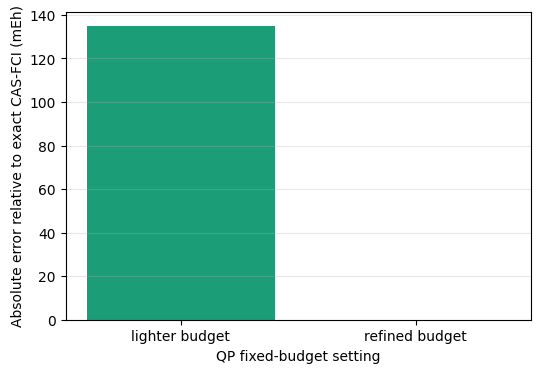

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(results_df["setting"], results_df["absolute_error_mEh"], color=["#1b9e77", "#d95f02"])
ax.set_ylabel("Absolute error relative to exact CAS-FCI (mEh)")
ax.set_xlabel("QP fixed-budget setting")
ax.grid(axis="y", alpha=0.3)
plt.show()


## Interpretation

This notebook keeps the same QP thick workflow as the small hydrogen examples, but now on a more realistic molecule.

- The active space is still small enough that exact CAS-FCI is available.
- Only the fixed-budget size changes between the two runs.
- The refined setting should reduce the error because it keeps and propagates more determinants.